# 02 · EDA: what the data says about how to model it

**Goal recap:** for each customer at a cutoff date, predict next-6-month `y_buy` (any purchase?) and `y_spend` (£), using only history up to the cutoff.

**This notebook's question:** *what about this customer base should change how we frame, split, featurize and evaluate?*
EDA here isn't a tour of the data. Every section ends with a **modelling implication**, and the final table is the hand-off to notebooks 03–07.

### Two ground rules
1. **Only data on or before the test cutoff (2011-06-09).** The test target window (Jun–Dec 2011) is never looked at, not even in a chart.
   If I saw that, say, Q4 2011 was huge, it could quietly influence my choices, which is leakage through the analyst's eyes rather than through the code.
2. **Unit of behaviour = a purchase *day*** (customer × date). Two invoices on the same day are one shopping occasion.
   Otherwise a split order would count as a "0-day gap" and inflate frequency.

### 🧠 Predict first
1. What's the **median** time between two purchases by the same customer: 1 week, 1 month, or 3 months?
2. A customer who hasn't bought for **5 months**: what's the chance they buy in the next 6? (10%? 30%? 50%+?)
3. Will the share of customers who buy again be **the same** whether we stand in June or in December? Why or why not?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from src.clean import CLEAN_PARQUET, RETURNS_PARQUET
from src.split import VAL_CUTOFF, TEST_CUTOFF, HORIZON_MONTHS, before_test

pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

purchases = before_test(pd.read_parquet(CLEAN_PARQUET))
returns = before_test(pd.read_parquet(RETURNS_PARQUET))

visits = (purchases.assign(day=purchases["InvoiceDate"].dt.normalize())
          .groupby(["Customer ID", "day"], as_index=False)
          .agg(spend=("Spend", "sum"), country=("Country", "first"))
          .sort_values(["Customer ID", "day"]))
cust = visits.groupby("Customer ID").agg(
    n_visits=("day", "size"), spend=("spend", "sum"),
    first_day=("day", "min"), last_day=("day", "max"), country=("country", "first"))

print(f"Data used: {purchases['InvoiceDate'].min().date()} → {purchases['InvoiceDate'].max().date()}")
print(f"{len(visits):,} purchase-days from {len(cust):,} customers")

Data used: 2009-12-01 → 2011-06-09
23,286 purchase-days from 4,942 customers


## 1. How concentrated is customer value?
**Why it matters:** if a few customers dominate revenue, the error metrics we choose will be dominated by them too.

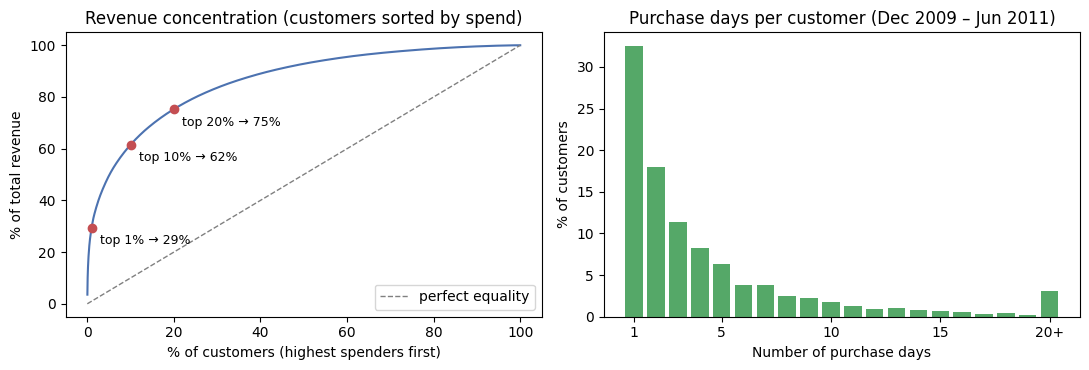

One-time buyers: 33% | median purchase days: 2


In [2]:
s = np.sort(cust["spend"].values)[::-1]
cum_share = s.cumsum() / s.sum()
cust_share = np.arange(1, len(s) + 1) / len(s)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(cust_share * 100, cum_share * 100, color="#4C72B0")
axes[0].plot([0, 100], [0, 100], ls="--", color="grey", lw=1, label="perfect equality")
for q in [0.01, 0.10, 0.20]:
    y = cum_share[int(q * len(s)) - 1]
    axes[0].scatter(q * 100, y * 100, color="#C44E52", zorder=3)
    axes[0].annotate(f"top {q:.0%} → {y:.0%}", (q * 100, y * 100), xytext=(6, -12), textcoords="offset points", fontsize=9)
axes[0].set_title("Revenue concentration (customers sorted by spend)")
axes[0].set_xlabel("% of customers (highest spenders first)")
axes[0].set_ylabel("% of total revenue")
axes[0].legend(loc="lower right")

counts = cust["n_visits"].clip(upper=20).value_counts().sort_index()
axes[1].bar(counts.index, counts.values / len(cust) * 100, color="#55A868")
axes[1].set_xticks([1, 5, 10, 15, 20], ["1", "5", "10", "15", "20+"])
axes[1].set_title("Purchase days per customer (Dec 2009 – Jun 2011)")
axes[1].set_xlabel("Number of purchase days")
axes[1].set_ylabel("% of customers")
plt.tight_layout()
plt.show()
print(f"One-time buyers: {(cust['n_visits'] == 1).mean():.0%} | median purchase days: {cust['n_visits'].median():.0f}")

**Takeaway:** the top 10% of customers drive about 62% of revenue (top 1% alone: 29%), and **a third of customers bought on only one day.**

**Implications:**
- **Metrics:** RMSE will be driven almost entirely by the few biggest customers. Report it, but lead with **rank metrics** (Spearman, decile lift, Gini).
  For targeting, *ordering* customers correctly is what matters.
- **Target shape:** many customers will have `y_spend = 0` and a few will have huge values, which is why log1p vs. Tweedie vs. hurdle is a real choice (notebook 07).
- **One-timers** have no inter-purchase gap at all, so gap features will be missing for them **by construction**, not at random (notebook 05).

## 2. How often do customers buy?
**Why it matters:** the gap between purchases tells us whether a **6-month** prediction window is long enough to see a "normal" repeat purchase, and which feature windows make sense.

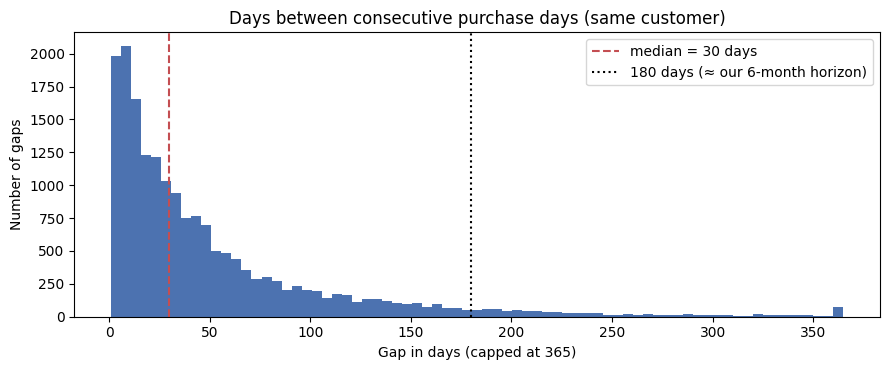

count    18344.0
mean        52.0
std         62.0
min          1.0
25%         12.0
50%         30.0
75%         66.0
90%        130.0
95%        179.0
max        540.0

Share of gaps ≤ 90 days: 83%   ≤ 180 days: 95%


In [3]:
gaps = visits.groupby("Customer ID")["day"].diff().dt.days.dropna()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(gaps.clip(upper=365), bins=73, color="#4C72B0")
med = gaps.median()
ax.axvline(med, color="#C44E52", ls="--", label=f"median = {med:.0f} days")
ax.axvline(180, color="black", ls=":", label="180 days (≈ our 6-month horizon)")
ax.set_title("Days between consecutive purchase days (same customer)")
ax.set_xlabel("Gap in days (capped at 365)")
ax.set_ylabel("Number of gaps")
ax.legend()
plt.tight_layout()
plt.show()

print(gaps.describe(percentiles=[.25, .5, .75, .9, .95]).round(0).to_string())
print(f"\nShare of gaps ≤ 90 days: {(gaps <= 90).mean():.0%}   ≤ 180 days: {(gaps <= 180).mean():.0%}")

**Takeaway:** the median gap is about **1 month**, and about **95% of repeat purchases happen within 180 days**.

**Implications:**
- A **6-month horizon is long enough**: a still-active customer will almost always buy within it. Using 1 month would label many healthy customers as "didn't buy".
  So `y_buy = 0` mostly means *really lapsed*, not *between orders*.
- **Feature windows of 30 / 90 / 180 days** cover the typical gap, one quarter, and nearly every gap.
- **Overdue ratio** (days since last purchase ÷ the customer's own typical gap) should be informative: 60 days of silence is alarming for a weekly buyer and normal for a quarterly one.
  Recency alone can't tell those two apart.

## 3. What does silence mean? (the core non-contractual question)
Since churn is never observed, the key question is: **given how long a customer has been quiet, how likely are they to come back?**
I measure it at one *training* cutoff, **2010-06-09**, whose target window (Jun–Dec 2010) ends before validation, so this uses no validation or test outcomes.

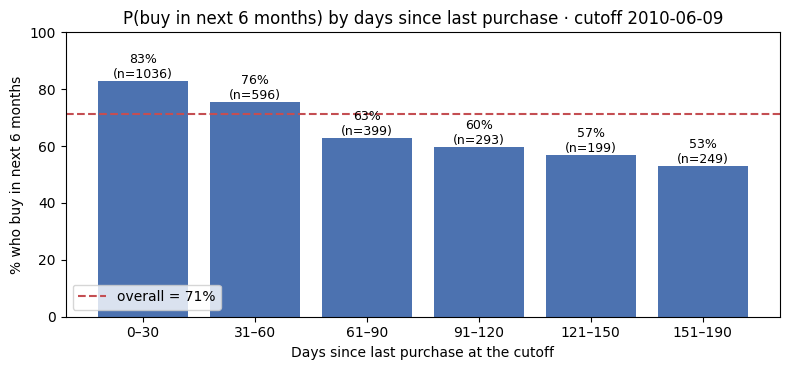

In [4]:
def snapshot(visits: pd.DataFrame, cutoff: pd.Timestamp, months: int = HORIZON_MONTHS) -> pd.DataFrame:
    # Quick EDA version of the snapshot table; the real builder lives in src/split.py (notebook 03).
    end = cutoff + pd.DateOffset(months=months)
    hist = visits[visits["day"] <= cutoff]
    future = visits[(visits["day"] > cutoff) & (visits["day"] <= end)]
    out = hist.groupby("Customer ID").agg(last_day=("day", "max"))
    out["recency_days"] = (cutoff - out["last_day"]).dt.days
    out["y_buy"] = out.index.isin(future["Customer ID"]).astype(int)
    return out


snap = snapshot(visits, pd.Timestamp("2010-06-09"))
bins = [-1, 30, 60, 90, 120, 150, 200]
labels = ["0–30", "31–60", "61–90", "91–120", "121–150", "151–190"]
curve = (snap.assign(recency=pd.cut(snap["recency_days"], bins, labels=labels))
         .groupby("recency", observed=True)["y_buy"].agg(buy_rate="mean", customers="size"))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(curve.index.astype(str), curve["buy_rate"] * 100, color="#4C72B0")
for i, (r, n) in enumerate(zip(curve["buy_rate"], curve["customers"])):
    ax.text(i, r * 100 + 1, f"{r:.0%}\n(n={n})", ha="center", fontsize=9)
ax.axhline(snap["y_buy"].mean() * 100, color="#C44E52", ls="--", label=f"overall = {snap['y_buy'].mean():.0%}")
ax.set_ylim(0, 100)
ax.set_title("P(buy in next 6 months) by days since last purchase · cutoff 2010-06-09")
ax.set_xlabel("Days since last purchase at the cutoff")
ax.set_ylabel("% who buy in next 6 months")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

**Takeaway:** buy-again probability falls steadily with recency, from about 83% for customers active in the last month to about 53% for those silent 5–6 months. The steepest drop is in the first 90 days; after that it flattens.
But **even long-silent customers come back about half the time**. Silence is evidence, not proof.

**Implications:**
- Recency will be the **strongest single feature**, and the naive baseline *"bought in last 90 days"* will be hard to beat. That's exactly why it's the baseline.
- The curve is **smooth and monotonic**, so a logistic regression with recency (perhaps log-transformed) can capture most of it. A GBM's edge has to come from *interactions*,
  like recency × typical gap.
- **Business framing:** "dormant 5 months" is *not* "churned". A retention campaign aimed at that group would hit about 50% who would have come back anyway.
  That's the case for modelling **uplift**, not just risk (a point to raise in notebook 12).

## 4. Seasonality: does the answer depend on *when* we stand?

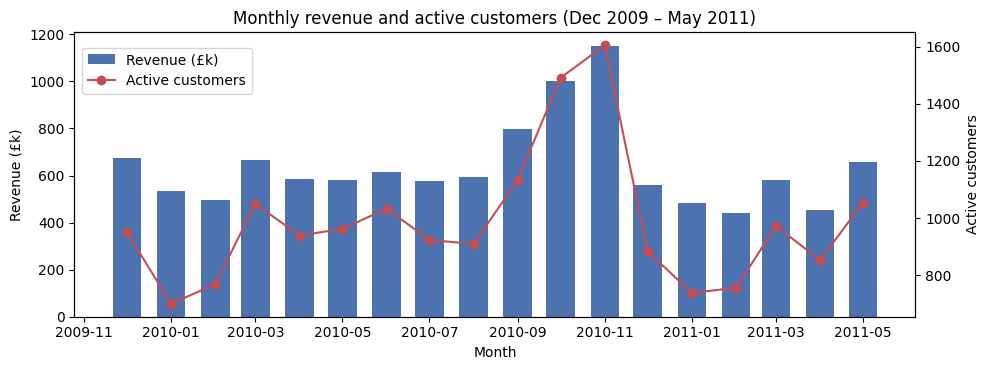

In [5]:
monthly = (purchases.set_index("InvoiceDate")
           .resample("MS").agg({"Spend": "sum", "Customer ID": "nunique"})
           .loc[: "2011-05-01"])  # June 2011 is only 9 days → excluded

fig, ax1 = plt.subplots(figsize=(10, 3.8))
ax1.bar(monthly.index, monthly["Spend"] / 1e3, width=20, color="#4C72B0", label="Revenue (£k)")
ax1.set_ylabel("Revenue (£k)")
ax2 = ax1.twinx()
ax2.plot(monthly.index, monthly["Customer ID"], color="#C44E52", marker="o", label="Active customers")
ax2.set_ylabel("Active customers")
ax1.set_title("Monthly revenue and active customers (Dec 2009 – May 2011)")
ax1.set_xlabel("Month")
fig.legend(loc="upper left", bbox_to_anchor=(0.08, 0.88))
plt.tight_layout()
plt.show()

**Takeaway:** Sep–Nov 2010 is the peak (Nov revenue is about 2× a typical spring month). This is trade customers stocking up for Christmas, followed by a quiet Jan–Feb.

Now the important part: the **base rate** of `y_buy` at different cutoff dates.
If seasonality matters, the share who buy in the next 6 months depends on whether that window contains a Q4.

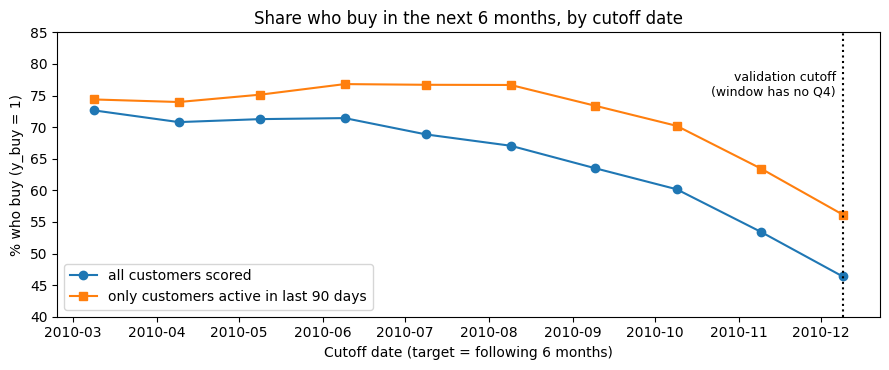

,all_customers,active_last_90d,share_silent_180d+,n
cutoff,,,,
2010-03-09,0.73,0.74,0.00,1853
2010-04-09,0.71,0.74,0.00,2212
2010-05-09,0.71,0.75,0.00,2492
2010-06-09,0.71,0.77,0.05,2772
2010-07-09,0.69,0.77,0.07,3010
2010-08-09,0.67,0.77,0.11,3178
2010-09-09,0.64,0.73,0.16,3348
2010-10-09,0.60,0.70,0.18,3643
2010-11-09,0.53,0.63,0.19,4006


In [6]:
cutoffs = pd.date_range("2010-03-01", "2010-12-01", freq="MS") + pd.Timedelta(days=8)  # the 9th of each month
rows = []
for c in cutoffs:
    sn = snapshot(visits, c)
    rows.append({"cutoff": c, "all_customers": sn["y_buy"].mean(),
                 "active_last_90d": sn.loc[sn["recency_days"] <= 90, "y_buy"].mean(),
                 "share_silent_180d+": (sn["recency_days"] > 180).mean(), "n": len(sn)})
base = pd.DataFrame(rows).set_index("cutoff")

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(base.index, base["all_customers"] * 100, marker="o", label="all customers scored")
ax.plot(base.index, base["active_last_90d"] * 100, marker="s", label="only customers active in last 90 days")
ax.axvline(VAL_CUTOFF, color="black", ls=":")
ax.annotate("validation cutoff\n(window has no Q4)", (VAL_CUTOFF, 75), ha="right", fontsize=9, xytext=(-5, 0), textcoords="offset points")
ax.set_ylim(40, 85)
ax.set_title("Share who buy in the next 6 months, by cutoff date")
ax.set_xlabel("Cutoff date (target = following 6 months)")
ax.set_ylabel("% who buy (y_buy = 1)")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()
base.round(2)

**Takeaway:** the buy-again rate falls from about **71% (June cutoff) to about 46% (December cutoff)**. Two things drive it:
1. **Pool dilution:** we score everyone who ever bought, so later cutoffs carry more long-dormant customers (0% silent 180+ days in spring vs. about 19% by December).
2. **Seasonality:** even among *recently active* customers the rate drops from about 77% to 56%. A June cutoff's window contains the Christmas season, so nearly every
   active trader reorders. A December cutoff's window is Dec–Jun: the trade customers have just finished their Q4 stocking, and many Q4-only buyers won't return until next autumn.

**Implications (this is the most important finding in the notebook):**
- **Validation ≠ test conditions.** The validation window (Dec 2010 → Jun 2011) has *no* Q4. The test window (Jun → Dec 2011) *does*, like the June 2010 training cutoff.
  So expect the test base rate to be much higher than validation's.
- Hence **calibration** (do predicted probabilities match reality?) checked on validation **won't transfer** to test, and a decision threshold set as "top X% by probability"
  will mean something different. **Ranking** quality (AUC) is more likely to hold up.
- **Mitigations:** add a **cutoff-month / "window contains Q4"** feature, and report validation metrics knowing they're from the off-season.
  During model selection, training cutoffs can only run Jan–Jun 2010 (their labels must mature before validation; see notebook 03).
  At the **final refit** (notebook 12), we train on cutoffs from **every month of 2010**, so the deployed model sees both seasons.
- **Interview line:** *"My validation and test windows had different seasonality, so I relied on rank metrics for model selection and treated calibration as something to re-check at deployment."*

## 5. A data-boundary trap: left-censored history

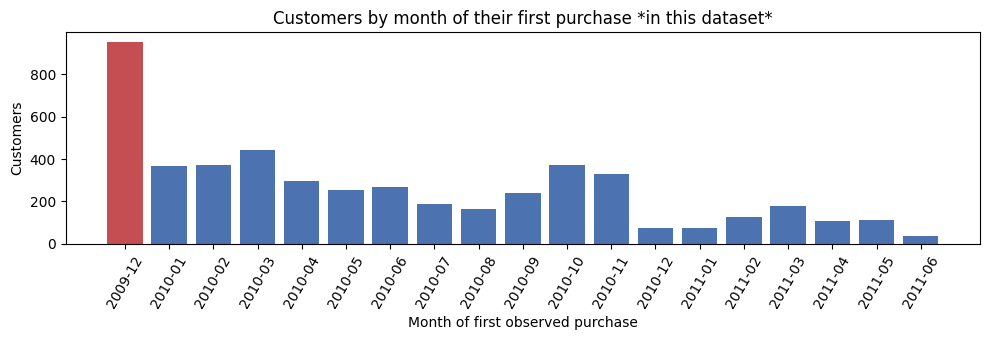

In [7]:
first_month = cust["first_day"].dt.to_period("M").value_counts().sort_index()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(first_month.index.astype(str), first_month.values,
       color=["#C44E52"] + ["#4C72B0"] * (len(first_month) - 1))
ax.set_title("Customers by month of their first purchase *in this dataset*")
ax.set_xlabel("Month of first observed purchase")
ax.set_ylabel("Customers")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

**Takeaway:** about 950 customers "first appear" in Dec 2009, roughly 3× any later month. They aren't new. **The data simply starts there**, and their earlier history is invisible (left-censoring).

**Implications:**
- **Tenure** ("days since first purchase") is **capped by the data start**: a 10-year customer looks like a 6-month one at a mid-2010 cutoff.
  Tenure means different things at different cutoffs, so add a **`history_truncated` flag** (first purchase within the first ~30 days of data).
- **Lifetime-so-far** features (total spend, total orders) are understated for early cutoffs, which is another reason to lean on fixed 30/90/180-day windows.
- The same trap happens at a real company after a **data migration or a new tracking system**: "new users" spike on day one.

## 6. Who are the customers? Order size, country, returns

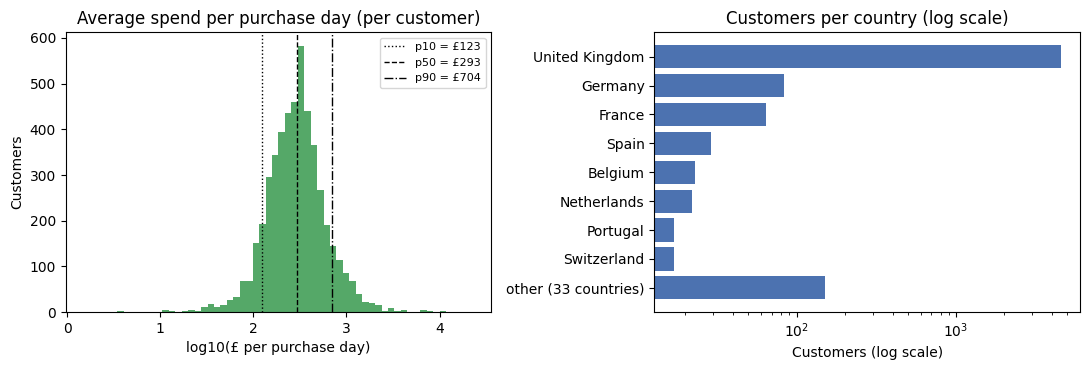

Countries: 41 | UK share of customers: 92% | countries with < 10 customers: 27
Customers with any return: 39% | return value / spend: median 0.0%, p90 4.5%, p99 33.1%


In [8]:
aov = visits.groupby("Customer ID")["spend"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(np.log10(aov), bins=60, color="#55A868")
for (q, v), ls in zip(aov.quantile([0.1, 0.5, 0.9]).items(), [":", "--", "-."]):
    axes[0].axvline(np.log10(v), color="black", ls=ls, lw=1, label=f"p{int(q*100)} = £{v:,.0f}")
axes[0].legend(fontsize=8)
axes[0].set_title("Average spend per purchase day (per customer)")
axes[0].set_xlabel("log10(£ per purchase day)")
axes[0].set_ylabel("Customers")

by_country = cust["country"].value_counts()
top = pd.concat([by_country.head(8), pd.Series({"other (33 countries)": by_country.iloc[8:].sum()})])
axes[1].barh(top.index[::-1], top.values[::-1], color="#4C72B0")
axes[1].set_xscale("log")
axes[1].set_title("Customers per country (log scale)")
axes[1].set_xlabel("Customers (log scale)")
plt.tight_layout()
plt.show()

print(f"Countries: {len(by_country)} | UK share of customers: {by_country.iloc[0] / len(cust):.0%} | "
      f"countries with < 10 customers: {(by_country < 10).sum()}")

ret_rate = (returns.groupby("Customer ID")["ReturnValue"].sum()
            .reindex(cust.index).fillna(0) / cust["spend"])
print(f"Customers with any return: {(ret_rate > 0).mean():.0%} | "
      f"return value / spend: median {ret_rate.median():.1%}, p90 {ret_rate.quantile(.9):.1%}, p99 {ret_rate.quantile(.99):.1%}")

**Takeaways and implications:**
- **Order size** varies about 6× between the 10th and 90th percentile (about £125 vs. £700 per purchase day; median about £290), even among identified customers. A typical "customer" here is a small business.
  Basket-size features (avg / max order value) help separate wholesalers from consumers, and should be **log-transformed** for linear and NN models (notebook 05).
- **Country:** about 92% UK and 41 levels, **27 of them with fewer than 10 customers**. One-hot encoding creates dozens of near-empty columns that a linear model will overfit.
  This sets up the encoding comparison in notebook 05: one-hot vs. rare-level grouping ("Other") vs. out-of-fold target encoding.
- **Returns:** about 40% of customers returned *something*, but the median return share is 0% and p90 is only a few percent. It's a **sparse, skewed** feature.
  It's probably weak overall, but it may flag a small group of problem accounts. Must be computed from **returns on or before the cutoff only**.

## 7. Summary: hand-off to the next notebooks

| Finding | Implication | Where |
|---|---|---|
| Top 10% ≈ 62% of revenue; a third are one-day buyers | Lead with rank metrics (Spearman, lift, Gini); zero-inflated spend target | 03, 07 |
| Median gap ≈ 1 month, ~95% of gaps ≤ 180 days | 6-month horizon is long enough; 30/90/180-day feature windows; overdue ratio | 03, 04 |
| P(buy) falls with recency (83% → 53%), but half of 5-month-silent customers return | Recency dominates; "active in 90 days" is a strong baseline; GBM must win via interactions | 03, 06 |
| Base rate 71% (June cutoff) vs. 46% (Dec cutoff) | Validation (no Q4) ≠ test (has Q4); select on ranking; seasonal feature; final refit on all months | 03, 05, 12 |
| Dec 2009 "new customer" spike = data start | Tenure is truncated → `history_truncated` flag; prefer fixed windows | 04 |
| 41 countries, 27 with < 10 customers | Encoding comparison: one-hot vs. rare-grouping vs. target encoding | 05 |
| Returns sparse (median 0%) | Weak, skewed feature; only pre-cutoff returns | 04 |

### 🧠 Interpret
1. Check your earlier predictions: median gap, the 5-month-silent buy rate, June vs. December. Which surprised you, and what did you assume that turned out wrong?
2. A PM says: *"Customers who haven't bought in 5 months are churned. Let's send them all a 20% discount."* Using section 3, explain in 2 sentences why this wastes money,
   and what you'd want to know instead.
3. Your model scores AUC 0.80 and is well calibrated on the **December** validation cutoff. Why might its predicted probabilities be **systematically too low** at the **June** test cutoff?
   Would AUC necessarily drop too?
4. At ARQ, what plays the role of Q4 seasonality? (Think: remittance spikes around holidays and month-end paydays, travel season for card spend, peso volatility events driving FX.)